# 02. Анализ экспериментов в MLflow

Все эксперименты запускаются стадией `train` DVC-пайплайна (`dvc repro` → `python -m src.models.train`) и логируются в MLflow:

* **5 алгоритмов** = 5 родительских runs (`run_kind = experiment`): параметры поиска, лучшие гиперпараметры, CV- и test-метрики, графики (ROC, PR, confusion matrix, калибровка, важность признаков), сама модель (`mlflow.sklearn.log_model`) и версии датасетов;
* **каждая проверенная комбинация гиперпараметров** = вложенный (nested) run (`run_kind = cv_candidate`) с CV ROC-AUC;
* **лучшая модель** зарегистрирована в Model Registry как `CreditDefaultModel` с алиасом `champion`.

Интерфейс MLflow открывается командой (из корня проекта):

```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
```

Ниже — тот же анализ программно, через MLflow API.

In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")

import matplotlib.pyplot as plt
import mlflow
import pandas as pd
import seaborn as sns
from IPython.display import Image, display
from mlflow import MlflowClient

ROOT = Path.cwd() if (Path.cwd() / "params.yaml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.config import RAW_FEATURES, TARGET, load_params
from src.models.evaluate import compute_metrics

params = load_params(ROOT / "params.yaml")
mlflow.set_tracking_uri(f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}")
experiment = mlflow.get_experiment_by_name(params["mlflow"]["experiment_name"])
runs = mlflow.search_runs(experiment_ids=[experiment.experiment_id])
sns.set_theme(style="whitegrid")
%matplotlib inline

print(f"Эксперимент '{experiment.name}': всего runs = {len(runs)}")
runs["tags.run_kind"].value_counts()

Эксперимент 'credit-default-pd': всего runs = 124


tags.run_kind
cv_candidate    114
experiment       10
Name: count, dtype: int64

## 1. Сравнение алгоритмов (родительские runs)

In [2]:
parents = (
    runs[runs["tags.run_kind"] == "experiment"]
    .sort_values("start_time", ascending=False)
    .drop_duplicates("tags.model_type")  # последний запуск каждого алгоритма
)
columns = {
    "tags.model_type": "model",
    "params.search_type": "search",
    "metrics.cv_roc_auc_mean": "cv_roc_auc",
    "metrics.cv_roc_auc_std": "cv_std",
    "metrics.test_roc_auc": "test_roc_auc",
    "metrics.test_gini": "test_gini",
    "metrics.test_ks": "test_ks",
    "metrics.test_pr_auc": "test_pr_auc",
    "metrics.test_brier": "brier",
    "params.decision_threshold": "threshold",
    "metrics.test_tuned_precision": "precision",
    "metrics.test_tuned_recall": "recall",
    "metrics.test_tuned_f1": "f1",
    "metrics.fit_time_sec": "fit_time_s",
}
comparison = (
    parents[list(columns)]
    .rename(columns=columns)
    .sort_values("cv_roc_auc", ascending=False)
    .reset_index(drop=True)
)
comparison.round(4)

,model,search,cv_roc_auc,cv_std,test_roc_auc,test_gini,test_ks,test_pr_auc,brier,threshold,precision,recall,f1,fit_time_s
0,hist_gradient_boosting,random,0.7890,0.0087,0.7793,0.5586,0.4250,0.5604,0.1350,0.2763,0.5118,0.5701,0.5394,11.6967
1,random_forest,random,0.7887,0.0086,0.7774,0.5547,0.4215,0.5576,0.1680,0.5377,0.5165,0.5543,0.5347,129.0685
2,gradient_boosting,random,0.7876,0.0089,0.7808,0.5615,0.4296,0.5669,0.1340,0.2969,0.5293,0.5445,0.5368,182.9240
3,extra_trees,random,0.7822,0.0079,0.7706,0.5412,0.4047,0.5449,0.1364,0.2392,0.4983,0.5603,0.5275,77.0200
4,logistic_regression,grid,0.7735,0.0089,0.7647,0.5295,0.4111,0.5303,0.1851,0.5628,0.5074,0.5445,0.5253,51.2810


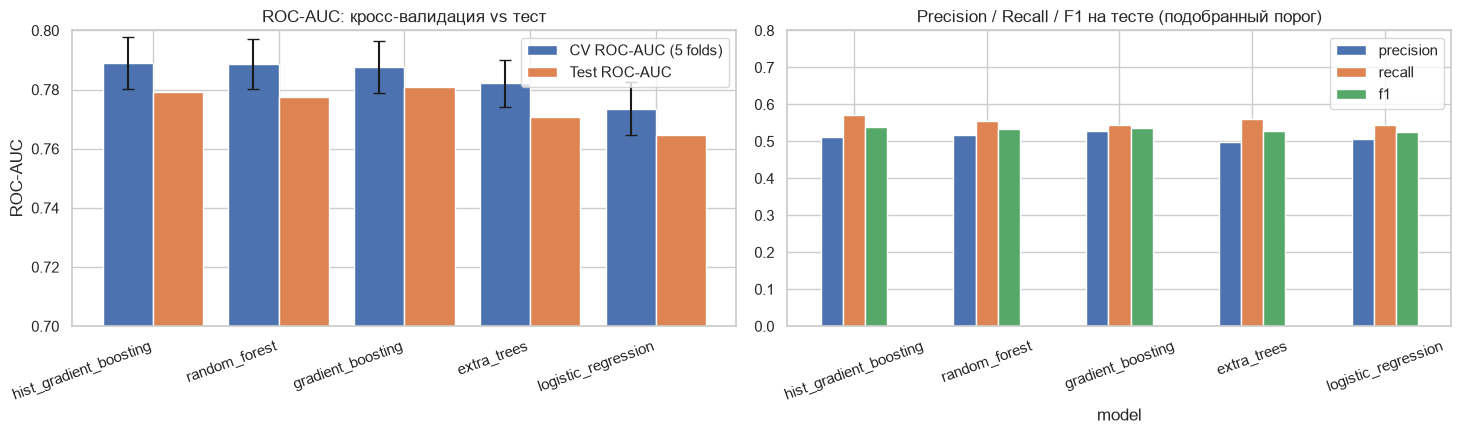

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
x = range(len(comparison))
axes[0].bar([i - 0.2 for i in x], comparison["cv_roc_auc"], 0.4, yerr=comparison["cv_std"], capsize=4, label="CV ROC-AUC (5 folds)")
axes[0].bar([i + 0.2 for i in x], comparison["test_roc_auc"], 0.4, label="Test ROC-AUC")
axes[0].set_xticks(list(x), comparison["model"], rotation=20, ha="right")
axes[0].set(ylim=(0.70, 0.80), title="ROC-AUC: кросс-валидация vs тест", ylabel="ROC-AUC")
axes[0].legend()

comparison.set_index("model")[["precision", "recall", "f1"]].plot.bar(ax=axes[1], rot=20)
axes[1].set(title="Precision / Recall / F1 на тесте (подобранный порог)", ylim=(0, 0.8))
plt.tight_layout()
plt.show()

## 2. Влияние гиперпараметров (вложенные runs)

Каждая точка — одна комбинация гиперпараметров, проверенная на 5-кратной кросс-валидации.

Проверено комбинаций гиперпараметров: 57


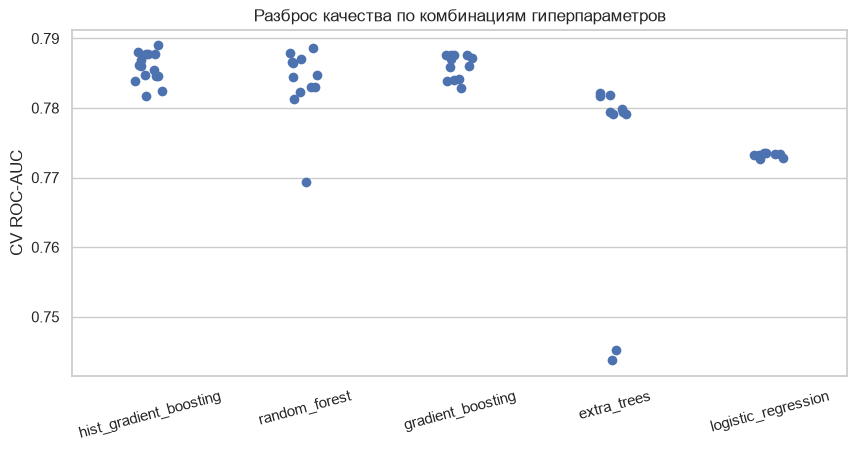

,count,min,max
tags.model_type,,,
extra_trees,10,0.7437,0.7822
gradient_boosting,12,0.7829,0.7876
hist_gradient_boosting,15,0.7818,0.7890
logistic_regression,8,0.7727,0.7735
random_forest,12,0.7693,0.7887


In [4]:
candidates = runs[runs["tags.run_kind"] == "cv_candidate"].copy()
latest_parents = set(parents["run_id"])
candidates = candidates[candidates["tags.mlflow.parentRunId"].isin(latest_parents)]
print("Проверено комбинаций гиперпараметров:", len(candidates))

fig, ax = plt.subplots(figsize=(10, 4.5))
order = comparison["model"].tolist()
sns.stripplot(data=candidates, x="tags.model_type", y="metrics.cv_roc_auc_mean", order=order, size=7, ax=ax)
ax.set(xlabel="", ylabel="CV ROC-AUC", title="Разброс качества по комбинациям гиперпараметров")
plt.xticks(rotation=15)
plt.show()

candidates.groupby("tags.model_type")["metrics.cv_roc_auc_mean"].agg(["count", "min", "max"]).round(4)

In [5]:
def candidate_table(model_type, param_names):
    table = candidates[candidates["tags.model_type"] == model_type]
    cols = [f"params.{p}" for p in param_names] + ["metrics.cv_roc_auc_mean", "metrics.cv_roc_auc_std"]
    return (
        table[cols]
        .rename(columns=lambda c: c.split(".", 1)[1])
        .sort_values("cv_roc_auc_mean", ascending=False)
        .reset_index(drop=True)
    )


print("Логистическая регрессия (GridSearchCV):")
display(candidate_table("logistic_regression", ["C", "class_weight"]).round(4))

print("Gradient Boosting (RandomizedSearchCV), топ-5:")
display(candidate_table("gradient_boosting", ["n_estimators", "learning_rate", "max_depth", "subsample", "min_samples_leaf"]).head().round(4))

print("Random Forest (RandomizedSearchCV), топ-5:")
display(candidate_table("random_forest", ["n_estimators", "max_depth", "min_samples_leaf", "max_features", "class_weight"]).head().round(4))

Логистическая регрессия (GridSearchCV):


,C,class_weight,cv_roc_auc_mean,cv_roc_auc_std
0,0.1,balanced,0.7735,0.0089
1,1.0,balanced,0.7735,0.0088
2,10.0,balanced,0.7734,0.0088
3,0.1,None,0.7733,0.0091
4,1.0,None,0.7733,0.0091
5,10.0,None,0.7732,0.0091
6,0.01,balanced,0.7728,0.0090
7,0.01,None,0.7727,0.0094


Gradient Boosting (RandomizedSearchCV), топ-5:


,n_estimators,learning_rate,max_depth,subsample,min_samples_leaf,cv_roc_auc_mean,cv_roc_auc_std
0,300,0.05,4,0.8,1,0.7876,0.0089
1,100,0.1,4,0.8,1,0.7876,0.0084
2,100,0.05,3,0.8,50,0.7876,0.0085
3,200,0.03,4,1.0,50,0.7876,0.0083
4,300,0.05,4,0.8,20,0.7872,0.0084


Random Forest (RandomizedSearchCV), топ-5:


,n_estimators,max_depth,min_samples_leaf,max_features,class_weight,cv_roc_auc_mean,cv_roc_auc_std
0,400,14,20,sqrt,balanced_subsample,0.7887,0.0086
1,200,10,20,sqrt,balanced_subsample,0.7879,0.0089
2,200,None,20,0.3,balanced_subsample,0.7871,0.0085
3,400,10,5,0.3,balanced_subsample,0.7866,0.0082
4,200,6,20,0.3,None,0.7864,0.0078


## 3. Модель-чемпион из MLflow Model Registry

In [6]:
client = MlflowClient()
name = params["mlflow"]["registered_model_name"]
champion = client.get_model_version_by_alias(name, "champion")
champion_run = client.get_run(champion.run_id)
print(f"{name} v{champion.version} (alias 'champion')")
print("Алгоритм:", champion_run.data.tags["model_type"])
print("Лучшие гиперпараметры:", {k: v for k, v in champion_run.data.params.items() if k.startswith("best_")})
print("Порог классификации:", champion_run.data.params["decision_threshold"])

# Загружаем модель прямо из реестра и проверяем на отложенной выборке
model = mlflow.sklearn.load_model(f"models:/{name}@champion")
test = pd.read_csv(ROOT / "data" / "processed" / "test.csv")
proba = model.predict_proba(test[RAW_FEATURES])[:, 1]
metrics = compute_metrics(test[TARGET], proba, threshold=float(champion_run.data.params["decision_threshold"]))
pd.Series(metrics).round(4).to_frame("test")

CreditDefaultModel v2 (alias 'champion')
Алгоритм: hist_gradient_boosting
Лучшие гиперпараметры: {'best_min_samples_leaf': '100', 'best_max_leaf_nodes': '15', 'best_max_iter': '400', 'best_learning_rate': '0.05', 'best_l2_regularization': '1.0'}
Порог классификации: 0.2763


,test
roc_auc,0.7793
gini,0.5586
ks,0.4250
pr_auc,0.5604
precision,0.5118
recall,0.5701
f1,0.5394
accuracy,0.7846
brier,0.1350
log_loss,0.4297


## 4. Графики лучшей модели (артефакты, залогированные в MLflow и версионируемые DVC)

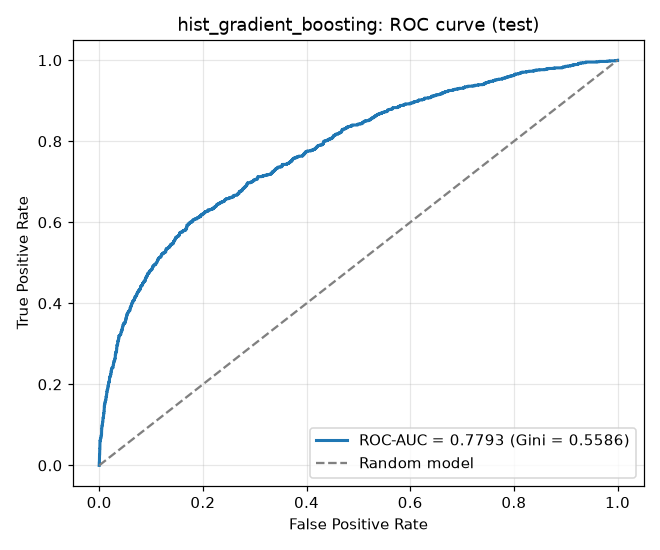

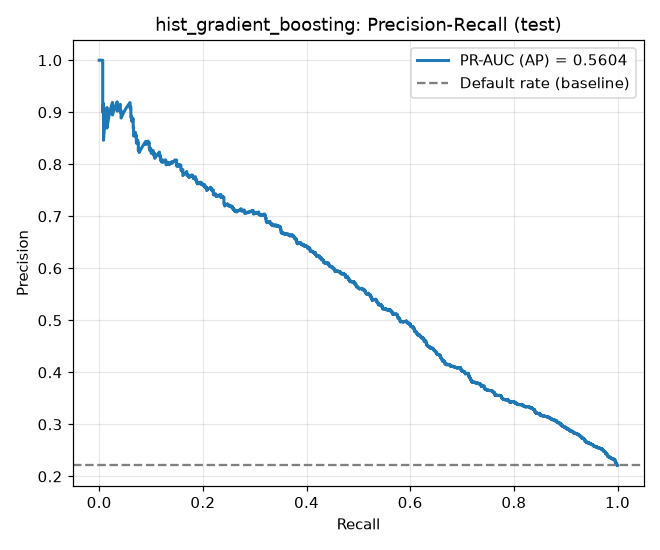

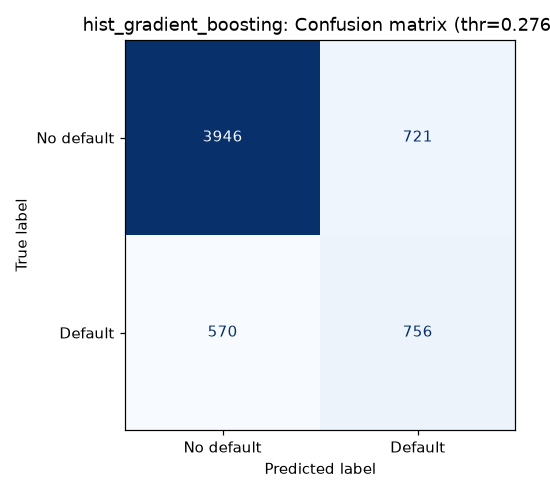

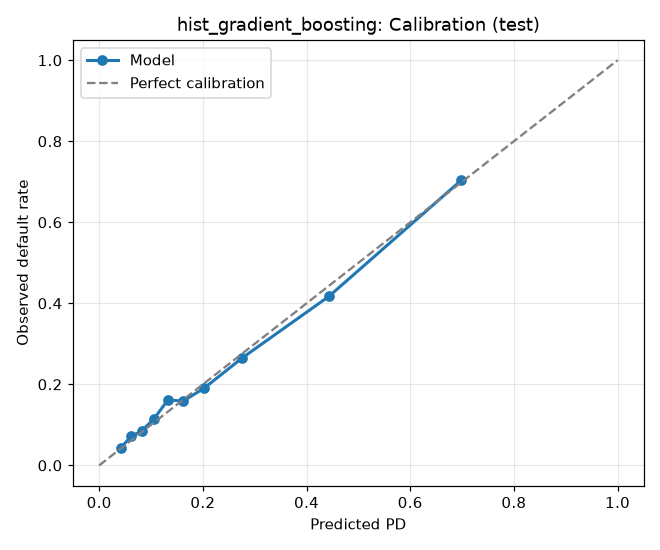

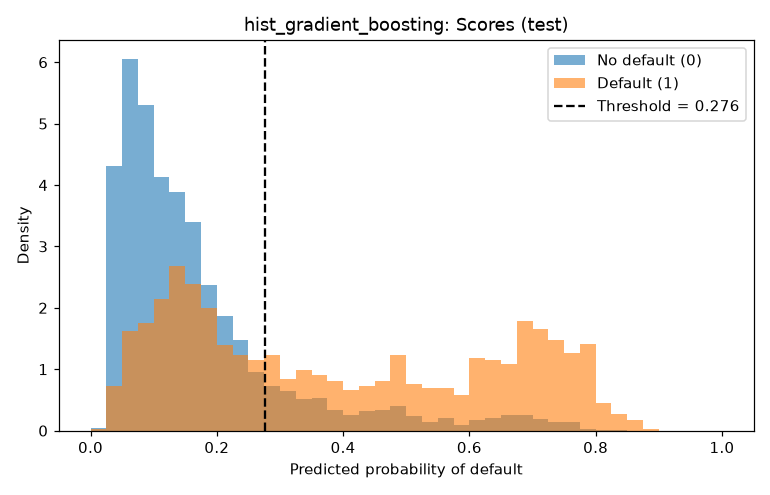

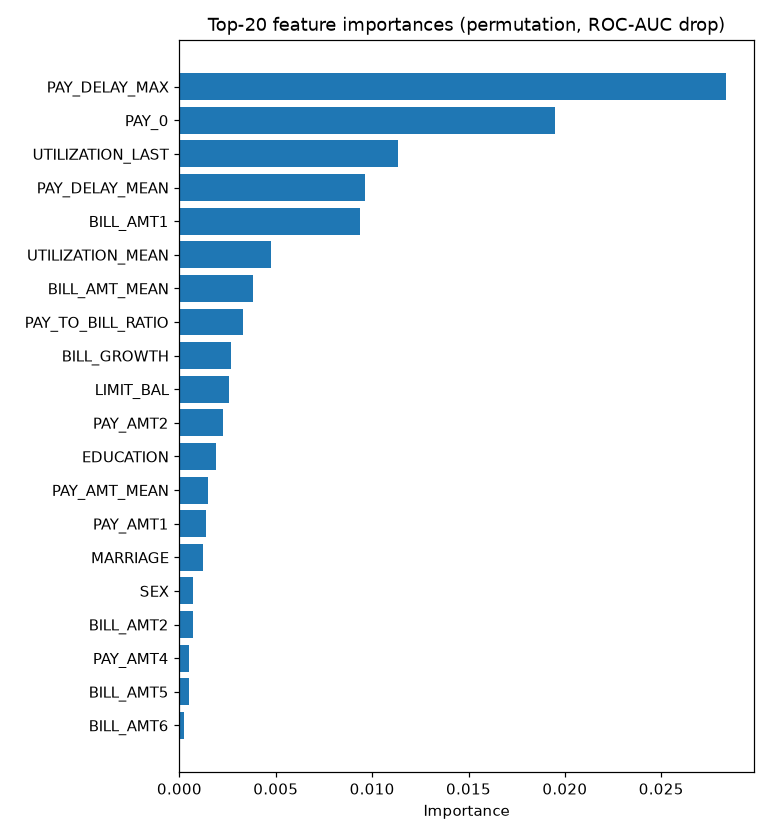

In [7]:
figures = ROOT / "reports" / "figures"
for name in ["roc_curve", "pr_curve", "confusion_matrix", "calibration_curve", "score_distribution", "feature_importance"]:
    display(Image(filename=str(figures / f"{name}.png"), width=520))

## 5. Выводы по экспериментам

1. **Все 5 алгоритмов** показывают CV ROC-AUC в диапазоне 0.773–0.789. Ансамбли деревьев лучше логистической регрессии примерно на 0.015: ключевые зависимости (история просрочек, возраст) нелинейны.
2. **Тройка лидеров статистически эквивалентна:** HistGradientBoosting (0.789), RandomForest (0.789) и GradientBoosting (0.788) различаются на 0.001–0.002 при стандартном отклонении по фолдам ≈0.009.
3. **Выбрана HistGradientBoosting** — лучшая по CV ROC-AUC. Дополнительные плюсы: подбор гиперпараметров в 10–15 раз быстрее (13 с против 2–3 минут) и хорошая калибровка вероятностей (Brier 0.135), что важно для PD-модели.
4. **Выбор по CV, а не по тесту.** На тесте у GradientBoosting ROC-AUC чуть выше (0.781 против 0.779), но такая разница меньше шума, а выбор модели по тестовой выборке сделал бы её оценку смещённой.
5. **Переобучения нет:** разрыв между CV и тестом ≈0.01 у всех алгоритмов.
6. **Гиперпараметры (вложенные runs, 57 комбинаций):** у логистической регрессии регуляризация почти не влияет (CV 0.7727–0.7735) — модель ограничена линейностью, а не переобучением; у Random Forest лучше всего крупные листья (`min_samples_leaf=20`) и `balanced_subsample`; Extra Trees наиболее чувствительны к настройкам (0.744–0.782); у Gradient Boosting многие конфигурации выходят на плато ≈0.7876 — дальнейший перебор сетки почти ничего не даст.
7. **`class_weight="balanced"`** выбран в лучших конфигурациях LogisticRegression и RandomForest: ранжирование лучше, но вероятности завышены (Brier 0.17–0.19), поэтому для них порог классификации получается около 0.55.
8. **Порог классификации** итоговой модели — 0.276 (максимум F1 на out-of-fold предсказаниях train). По сравнению с порогом 0.5 recall растёт с 0.37 до 0.57, F1 — с 0.47 до 0.54.
9. **Модель из Model Registry** (`CreditDefaultModel@champion`) загружается напрямую из MLflow и воспроизводит метрики из `reports/metrics.json` — реестр можно использовать как источник модели для деплоя.